# COS802: Cross-Lingual NER for South African Bantu Languages
**Mpendulo Sibeko (19144832)**

This notebook contains the full experiment for the report *Language, Domain, or Pretraining Exposure? Cross-Lingual NER for South African Bantu Languages*. AfroXLMR-base is fine-tuned on one source corpus at a time and evaluated on nine test sets from NCHLT (government text) and MasakhaNER 2.0 (news).

| | Research question |
|---|---|
| RQ1 | Does linguistic relatedness or domain match better predict zero-shot transfer? |
| RQ2 | Do targets seen in pretraining transfer better than unseen targets? |
| RQ3 | How far do 100 and 500 target sentences close transfer gaps? |
| RQ4 | Are Sepedi and Sesotho stronger Setswana sources than Swahili and Chichewa? |

Run the notebook from top to bottom on a GPU runtime (Colab T4).

## 1. Environment setup
On Colab, uncomment and run the next cell once, then restart the runtime. Locally, install the packages in `requirements.txt`.

In [ ]:
# # 1. Force-reinstall numpy first to align the binary headers
# !uv pip install --refresh --force-reinstall numpy

# # 2. Pre-install necessary compilation tools
# !uv pip install -q -U "setuptools<82" wheel Cython jedi

# # 3. Installing modern packages & seqeval
# !uv pip install -U datasets transformers accelerate evaluate nervaluate statsmodels seaborn seqeval

# # 4. Automatically trigger a Colab runtime restart safely
# import os
# print("\n--> Installation complete! Automatically restarting runtime to apply changes...")
# os.kill(os.getpid(), 9)


## 2. Imports and configuration
Paths, model, seeds, the source cap and training settings. `DRY_RUN = True` runs a small version of the whole pipeline.

In [ ]:
# Standard library
import copy
import io
import json
import math
import os
import random
import zipfile
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

# Data and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

In [ ]:
# ---------- Paths ----------
PROJECT_DIR = Path.cwd()
DATA_DIR = PROJECT_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
NCHLT_DIR = RAW_DIR / "nchlt"            # put the SADiLaR NCHLT files here (see 3.2)
MASAKHANE_DIR = RAW_DIR / "masakhaner2"  # cache for MasakhaNER 2.0 files
SPLIT_DIR = DATA_DIR / "splits"          # our fixed NCHLT splits are saved here
RESULTS_DIR = PROJECT_DIR / "results"
PRED_DIR = RESULTS_DIR / "per_sentence"  # per-sentence counts for bootstrap tests
FIG_DIR = PROJECT_DIR / "figures"

for d in [NCHLT_DIR, MASAKHANE_DIR, SPLIT_DIR, RESULTS_DIR, PRED_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ---------- Run mode ----------
DRY_RUN = False  # True = tiny data and grid for testing; False = full experiment

# ---------- Model ----------
MODEL_NAME = "Davlan/afro-xlmr-base"
MAX_LENGTH = 128

# ---------- Experiment settings ----------
SEEDS = [13, 42, 2026] if not DRY_RUN else [13]
SOURCE_CAP = 3000 if not DRY_RUN else 1000      # sentences per source (equalises data size)
FEWSHOT_SIZES = [100, 500] if not DRY_RUN else [50]
NCHLT_SPLIT = (0.8, 0.1, 0.1)
NCHLT_SPLIT_SEED = 802                           # fixed once, never changed

# ---------- Training hyperparameters (fixed epochs, no checkpoint selection on target data) ----------
TRAIN_ARGS = dict(
    learning_rate=5e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    weight_decay=0.01,
    num_train_epochs=3,
)
FEWSHOT_EPOCHS = {100: 10, 500: 5, 50: 2}

print("DRY_RUN:", DRY_RUN, "| seeds:", SEEDS, "| source cap:", SOURCE_CAP)

DRY_RUN: False | seeds: [13, 42, 2026] | source cap: 3000


In [ ]:
# ---------- Google Drive backup (Colab) ----------
# Colab wipes /content when a runtime is recycled, so results are mirrored to Drive (section 9).
BACKUP_ROOT = Path("/content/drive/MyDrive/COS802_project_backup")
BACKUP_RESULTS = BACKUP_ROOT / "v2_deduplicated" / "results"   # the deduplicated run (section 6.0)
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BACKUP_RESULTS.mkdir(parents=True, exist_ok=True)
    print("Drive mounted; results are backed up to", BACKUP_RESULTS)
except Exception as e:
    BACKUP_RESULTS = None
    print("No Drive backup (not on Colab, or the mount failed):", e)

Mounted at /content/drive
Drive mounted; results are backed up to /content/drive/MyDrive/COS802_project_backup/v2_deduplicated/results


### 2.1 Language metadata
Cluster, writing system and pretraining exposure for each language. A language is *seen* if it is in AfroXLMR's adaptation corpus (Alabi et al., 2022).

In [ ]:
LANGS = pd.DataFrame([
    # code, name,       cluster,         writing,        exposure_binary, exposure_graded
    ("zul", "isiZulu",  "Nguni",         "conjunctive",  1, 1),
    ("xho", "isiXhosa", "Nguni",         "conjunctive",  1, 2),
    ("ssw", "Siswati",  "Nguni",         "conjunctive",  0, 0),
    ("nso", "Sepedi",   "Sotho-Tswana",  "disjunctive",  0, 0),
    ("sot", "Sesotho",  "Sotho-Tswana",  "disjunctive",  1, 1),
    ("tsn", "Setswana", "Sotho-Tswana",  "disjunctive",  0, 0),
    ("swa", "Swahili",  "Other Bantu",   "-",            1, 2),
    ("nya", "Chichewa", "Other Bantu",   "-",            1, 1),
], columns=["code", "name", "cluster", "writing", "exposure_binary", "exposure_graded"]).set_index("code")

TARGET_LANGS = ["zul", "xho", "ssw", "nso", "sot", "tsn"]
NEWS_TARGETS = ["zul", "xho", "tsn"]
LANGS

,name,cluster,writing,exposure_binary,exposure_graded
code,,,,,
zul,isiZulu,Nguni,conjunctive,1,1
xho,isiXhosa,Nguni,conjunctive,1,2
ssw,Siswati,Nguni,conjunctive,0,0
nso,Sepedi,Sotho-Tswana,disjunctive,0,0
sot,Sesotho,Sotho-Tswana,disjunctive,1,1
tsn,Setswana,Sotho-Tswana,disjunctive,0,0
swa,Swahili,Other Bantu,-,1,2
nya,Chichewa,Other Bantu,-,1,1


In [ ]:
def relatedness(src, tgt):
    # Ordered levels used as the relatedness variable (higher = closer).
    if src == tgt:
        return "same_language"
    cs, ct = LANGS.loc[src, "cluster"], LANGS.loc[tgt, "cluster"]
    if cs == ct:
        return "same_cluster"
    if {cs, ct} <= {"Nguni", "Sotho-Tswana"}:
        return "other_southern_bantu"
    return "other_bantu"

REL_ORDER = ["same_language", "same_cluster", "other_southern_bantu", "other_bantu"]
REL_SCORE = {"same_language": 3, "same_cluster": 2, "other_southern_bantu": 1, "other_bantu": 0}

# Quick check
print(relatedness("xho", "zul"), relatedness("nso", "tsn"), relatedness("zul", "tsn"), relatedness("swa", "tsn"))

same_cluster same_cluster other_southern_bantu other_bantu


## 3. Data acquisition
Every corpus is loaded into the same format: a list of sentences with `tokens` and `tags`.

### 3.1 MasakhaNER 2.0 (news, CC BY-NC 4.0)
isiZulu, isiXhosa and Setswana are targets and sources; Swahili and Chichewa are sources only.

In [ ]:
MASAKHANE_LANGS = ["zul", "xho", "tsn", "swa", "nya"]
MASAKHANE_GITHUB = "https://raw.githubusercontent.com/masakhane-io/masakhane-ner/main/MasakhaNER2.0/data/{lang}/{split}.txt"
HF_NAME = "masakhane/masakhaner2"

def read_conll(text):
    # Parse "token tag" lines with blank lines between sentences.
    sents, toks, tags = [], [], []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("-DOCSTART-"):
            if toks:
                sents.append({"tokens": toks, "tags": tags})
                toks, tags = [], []
            continue
        parts = line.split()
        if len(parts) < 2:
            continue
        toks.append(parts[0])
        tags.append(parts[-1])
    if toks:
        sents.append({"tokens": toks, "tags": tags})
    return sents

def load_masakhaner(lang):
    out = {}
    try:
        from datasets import load_dataset
        try:
            ds = load_dataset(HF_NAME, lang)
        except Exception:
            ds = load_dataset(HF_NAME, lang, trust_remote_code=True)
        names = ds["train"].features["ner_tags"].feature.names
        for split, hf_split in [("train", "train"), ("dev", "validation"), ("test", "test")]:
            out[split] = [{"tokens": r["tokens"], "tags": [names[i] for i in r["ner_tags"]]} for r in ds[hf_split]]
        print(f"{lang}: loaded from Hugging Face")
        return out
    except Exception as e:
        print(f"{lang}: Hugging Face failed ({type(e).__name__}); trying GitHub")
    import requests
    for split in ["train", "dev", "test"]:
        cache = MASAKHANE_DIR / lang / f"{split}.txt"
        if not cache.exists():
            cache.parent.mkdir(parents=True, exist_ok=True)
            r = requests.get(MASAKHANE_GITHUB.format(lang=lang, split=split), timeout=60)
            r.raise_for_status()
            cache.write_text(r.text, encoding="utf-8")
        out[split] = read_conll(cache.read_text(encoding="utf-8"))
    print(f"{lang}: loaded from GitHub cache")
    return out

In [ ]:
masakhane = {lang: load_masakhaner(lang) for lang in MASAKHANE_LANGS}

for lang, d in masakhane.items():
    print(lang, {k: len(v) for k, v in d.items()})

README.md:   0%|          | 0.00/8.62k [00:00<?, ?B/s]

masakhaner2.py:   0%|          | 0.00/8.79k [00:00<?, ?B/s]

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


zul: Hugging Face failed (RuntimeError); trying GitHub


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


zul: loaded from GitHub cache
xho: Hugging Face failed (RuntimeError); trying GitHub


... (2 outputs left out)

`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


tsn: loaded from GitHub cache
swa: Hugging Face failed (RuntimeError); trying GitHub


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'masakhane/masakhaner2' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


swa: loaded from GitHub cache
nya: Hugging Face failed (RuntimeError); trying GitHub
nya: loaded from GitHub cache
zul {'train': 5848, 'dev': 836, 'test': 1670}
xho {'train': 5718, 'dev': 817, 'test': 1633}
tsn {'train': 3489, 'dev': 499, 'test': 996}
swa {'train': 6593, 'dev': 942, 'test': 1883}
nya {'train': 6250, 'dev': 893, 'test': 1785}


### 3.2 NCHLT NER (government text, CC BY 2.5 ZA)
The six NCHLT corpora are downloaded from SADiLaR's repository. NCHLT has no official split, so one is created in section 6.

In [ ]:
def read_nchlt_text(text):
    # NCHLT: tab-separated "token<TAB>tag" (sometimes extra columns), blank line between sentences.
    sents, toks, tags = [], [], []
    for line in text.splitlines():
        line = line.rstrip("\n").strip("﻿")
        if not line.strip():
            if toks:
                sents.append({"tokens": toks, "tags": tags})
                toks, tags = [], []
            continue
        parts = line.split("\t") if "\t" in line else line.split()
        if len(parts) < 2:
            continue
        toks.append(parts[0].strip())
        tags.append(parts[-1].strip())
    if toks:
        sents.append({"tokens": toks, "tags": tags})
    return sents

def load_nchlt(lang):
    folder = NCHLT_DIR / lang
    texts = []
    for p in sorted(folder.rglob("*")):
        if p.suffix.lower() == ".zip":
            with zipfile.ZipFile(p) as z:
                for name in z.namelist():
                    if name.lower().endswith((".txt", ".tsv", ".conll")) and "readme" not in name.lower() and "licen" not in name.lower():
                        texts.append(z.read(name).decode("utf-8", errors="replace"))
        elif p.suffix.lower() in (".txt", ".tsv", ".conll") and "readme" not in p.name.lower() and "licen" not in p.name.lower():
            texts.append(p.read_text(encoding="utf-8", errors="replace"))
    sents = [s for t in texts for s in read_nchlt_text(t)]
    if not sents:
        print(f"{lang}: no NCHLT files found in {folder}")
    return sents

In [ ]:
# Download the six NCHLT NER corpora from SADiLaR's public API (CC BY 2.5 ZA). Skips languages already present,
# so it is safe to re-run; needed on every fresh Colab runtime, because /content is wiped when a runtime is recycled.
import requests, zipfile
ITEMS = {
    "zul": "2afd4bfa-77d9-46d6-b493-04e7ac6416c3",
    "xho": "2faee276-ee6b-4690-adaa-0c4151d1cca1",
    "ssw": "6c516d94-b3ae-463e-945c-58a0ad5bc85a",
    "nso": "7331861f-d9f1-490f-8306-5a54f2b98b83",
    "sot": "b8c6bb58-d6ea-451d-ba47-01a90daac161",
    "tsn": "9320bd1a-aeb5-4ed2-8885-08a529d1f814",
}
for lang, uuid in ITEMS.items():
    out = NCHLT_DIR / lang
    out.mkdir(parents=True, exist_ok=True)
    if any(out.glob("*.zip")):
        print(lang, "already downloaded"); continue
    bundles = requests.get(f"https://repo.sadilar.org/server/api/core/items/{uuid}/bundles", timeout=60).json()
    orig = next(b for b in bundles["_embedded"]["bundles"] if b["name"] == "ORIGINAL")
    bs = requests.get(orig["_links"]["bitstreams"]["href"], timeout=60).json()["_embedded"]["bitstreams"]
    for b in bs:
        if not b["name"].lower().endswith(".zip"):
            continue
        r = requests.get(f"https://repo.sadilar.org/bitstreams/{b['uuid']}/download", timeout=300)
        r.raise_for_status()
        (out / b["name"]).write_bytes(r.content)
        print(lang, b["name"], f"{len(r.content)/1e6:.1f} MB", zipfile.is_zipfile(out / b["name"]))

zul nchlt_isizulu_named_entity_annotated_corpus.zip 25.1 MB True
xho nchlt_isixhosa_named_entity_annotated_corpus.zip 14.5 MB True
ssw nchlt_siswati_named_entity_annotated_corpus.zip 21.9 MB True
nso nchlt_sepedi_named_entity_annotated_corpus.zip 22.1 MB True
sot nchlt_sesotho_named_entity_annotated_corpus.zip 30.4 MB True
tsn nchlt_setswana_named_entity_annotated_corpus.zip 25.9 MB True


In [ ]:
nchlt_all = {lang: load_nchlt(lang) for lang in TARGET_LANGS}

for lang, sents in nchlt_all.items():
    tag_set = Counter(t for s in sents for t in s["tags"])
    print(f"{lang}: {len(sents):>6} sentences | tags: {dict(tag_set.most_common(10))}")

# Stop here rather than silently running a smaller experiment: section 8 drops any corpus that did not load.
missing_nchlt = [lang for lang, s in nchlt_all.items() if not s]
assert not missing_nchlt, f"NCHLT data missing for {missing_nchlt}: run the download cell above (or add the ZIPs by hand)"

zul:  10955 sentences | tags: {'OUT': 169285, 'B-MISC': 10805, 'I-MISC': 7419, 'B-PERS': 3701, 'B-LOC': 3156, 'B-ORG': 3018, 'I-ORG': 1991, 'I-PERS': 1249, 'I-LOC': 707}
xho:   6283 sentences | tags: {'OUT': 101769, 'B-MISC': 10211, 'I-MISC': 3365, 'I-ORG': 1365, 'B-LOC': 1222, 'B-ORG': 1182, 'B-PERS': 972, 'I-LOC': 824, 'I-PERS': 256}
ssw:  10797 sentences | tags: {'OUT': 147972, 'B-MISC': 7855, 'B-PERS': 4588, 'I-MISC': 4484, 'B-ORG': 3479, 'I-ORG': 2503, 'B-LOC': 2322, 'I-LOC': 1223, 'I-PERS': 952}
nso:   7116 sentences | tags: {'OUT': 176882, 'I-MISC': 5373, 'I-ORG': 4961, 'B-MISC': 4529, 'B-PERS': 2846, 'B-ORG': 2721, 'I-PERS': 1707, 'B-LOC': 1619, 'I-LOC': 793}
sot:   9471 sentences | tags: {'OUT': 245566, 'B-MISC': 6093, 'I-MISC': 5124, 'I-ORG': 3330, 'B-PERS': 3070, 'B-ORG': 2765, 'B-LOC': 1987, 'I-LOC': 918, 'I-PERS': 771}
tsn:   7943 sentences | tags: {'OUT': 207654, 'B-MISC': 7782, 'I-MISC': 7177, 'B-PERS': 2046, 'B-LOC': 1810, 'I-ORG': 1686, 'I-PERS': 1205, 'B-ORG': 1079, '

## 4. Label harmonisation
Both corpora are mapped to PER, LOC and ORG. NCHLT `MISC` and MasakhaNER `DATE` spans are masked: they are ignored in the loss and in scoring, not relabelled as `O`.

Check that every NCHLT language folder is populated.

In [ ]:
import os
for lang in TARGET_LANGS:
    path = NCHLT_DIR / lang
    exists = path.exists() and len(list(path.glob('*'))) > 0
    print(f"{lang.upper()} NCHLT path {path} populated: {exists}")

ZUL NCHLT path /content/data/raw/nchlt/zul populated: False
XHO NCHLT path /content/data/raw/nchlt/xho populated: False
SSW NCHLT path /content/data/raw/nchlt/ssw populated: False
NSO NCHLT path /content/data/raw/nchlt/nso populated: False
SOT NCHLT path /content/data/raw/nchlt/sot populated: False
TSN NCHLT path /content/data/raw/nchlt/tsn populated: False


In [ ]:
LABELS = ["O", "B-PER", "I-PER", "B-LOC", "I-LOC", "B-ORG", "I-ORG"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}
IGNORE = "IGN"  # marker for excluded MISC/DATE tokens

TYPE_MAP = {"PER": "PER", "PERS": "PER", "PERSON": "PER",
            "LOC": "LOC", "LOCATION": "LOC",
            "ORG": "ORG", "ORGANISATION": "ORG", "ORGANIZATION": "ORG"}
EXCLUDED_TYPES = {"MISC", "DATE"}

def harmonise_tag(tag):
    t = tag.strip().upper()
    if t in {"O", "OUT", ""}:
        return "O"
    if "-" in t:
        prefix, etype = t.split("-", 1)
    else:
        prefix, etype = "B", t
    prefix = "B" if prefix in {"B", "S"} else "I"
    if etype in EXCLUDED_TYPES:
        return IGNORE
    if etype in TYPE_MAP:
        return f"{prefix}-{TYPE_MAP[etype]}"
    return IGNORE  # unknown types are excluded rather than guessed

def harmonise_sentences(sents):
    return [{"tokens": s["tokens"], "tags": [harmonise_tag(t) for t in s["tags"]]} for s in sents]

# Self-test
print([harmonise_tag(t) for t in ["OUT", "B-PERS", "I-PERS", "B-MISC", "I-DATE", "B-ORG", "O"]])

['O', 'B-PER', 'I-PER', 'IGN', 'IGN', 'B-ORG', 'O']


In [ ]:
masakhane_h = {lang: {split: harmonise_sentences(s) for split, s in d.items()} for lang, d in masakhane.items()}
nchlt_h = {lang: harmonise_sentences(s) for lang, s in nchlt_all.items()}

print("Example (MasakhaNER zul):", list(zip(masakhane_h["zul"]["train"][0]["tokens"][:12], masakhane_h["zul"]["train"][0]["tags"][:12])))

Example (MasakhaNER zul): [('Ngesizini', 'O'), ('edlule', 'O'), ('baphelela', 'O'), ('endaweni', 'O'), ('yesi', 'O'), ('-', 'O'), ('12', 'O'), ('namaphuzu', 'O'), ('awu', 'O'), ('-', 'O'), ('34', 'O'), ('.', 'O')]


## 5. Exploratory data analysis
### 5.1 Corpus sizes

In [ ]:
def entity_spans(tags):
    # Return a list of (type, start, end) entity spans from BIO tags (conlleval style; IGN ends a span).
    spans, etype, start = [], None, None
    for i, t in enumerate(list(tags) + ["O"]):
        if t.startswith("B-") or t in ("O", IGNORE) or (t.startswith("I-") and t[2:] != etype):
            if etype is not None:
                spans.append((etype, start, i))
                etype, start = None, None
            if t.startswith("B-") or t.startswith("I-"):
                etype, start = t[2:], i
    return spans

def corpus_stats(sents, name):
    n_tok = sum(len(s["tokens"]) for s in sents)
    ents = Counter(e[0] for s in sents for e in entity_spans(s["tags"]))
    ign = sum(t == IGNORE for s in sents for t in s["tags"])
    with_ent = sum(1 for s in sents if entity_spans(s["tags"]))
    return {"corpus": name, "sentences": len(sents), "tokens": n_tok,
            "PER": ents["PER"], "LOC": ents["LOC"], "ORG": ents["ORG"],
            "excluded_tokens": ign,
            "pct_sent_with_entity": round(100 * with_ent / max(len(sents), 1), 1),
            "mean_len": round(n_tok / max(len(sents), 1), 1)}

rows = []
for lang, d in masakhane_h.items():
    for split, s in d.items():
        rows.append({"lang": lang, "split": split, **corpus_stats(s, "MasakhaNER")})
for lang, s in nchlt_h.items():
    rows.append({"lang": lang, "split": "all", **corpus_stats(s, "NCHLT")})

stats_df = pd.DataFrame(rows)
stats_df

,lang,split,corpus,sentences,tokens,PER,LOC,ORG,excluded_tokens,pct_sent_with_entity,mean_len
0,zul,train,MasakhaNER,5848,89355,1660,886,2212,1224,42.5,15.3
1,zul,dev,MasakhaNER,836,13245,603,95,265,258,59.4,15.8
2,zul,test,MasakhaNER,1670,26086,888,337,373,528,55.3,15.6
3,xho,train,MasakhaNER,5718,86645,3211,1133,1720,1407,54.0,15.2
4,xho,dev,MasakhaNER,817,14246,872,277,612,442,81.5,17.4
5,xho,test,MasakhaNER,1633,26326,1173,539,841,584,70.8,16.1
6,tsn,train,MasakhaNER,3489,99973,1732,1244,1120,2378,60.6,28.7
7,tsn,dev,MasakhaNER,499,14389,258,156,158,362,58.9,28.8
8,tsn,test,MasakhaNER,996,26705,614,248,465,450,69.3,26.8
9,swa,train,MasakhaNER,6593,175160,3875,6111,2327,3856,76.4,26.6


### 5.2 Entity type distribution

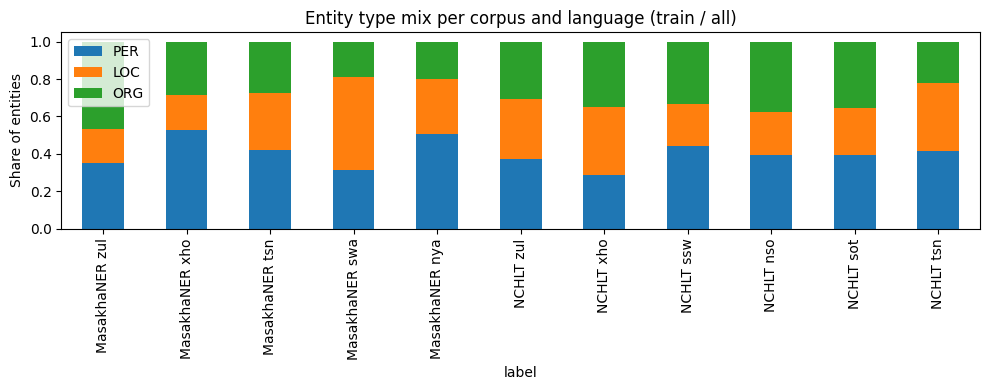

In [ ]:
plot_df = stats_df[(stats_df["split"].isin(["train", "all"]))].copy()
plot_df["label"] = plot_df["corpus"] + " " + plot_df["lang"]
ax = plot_df.set_index("label")[["PER", "LOC", "ORG"]].div(plot_df.set_index("label")[["PER", "LOC", "ORG"]].sum(axis=1), axis=0).plot(
    kind="bar", stacked=True, figsize=(10, 4))
ax.set_ylabel("Share of entities")
ax.set_title("Entity type mix per corpus and language (train / all)")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_entity_mix.png", dpi=150)
plt.show()

### 5.3 Sentence length

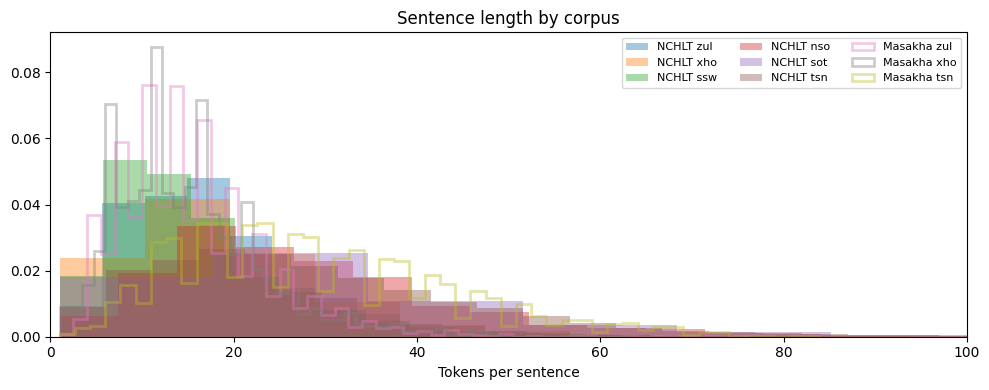

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for lang, s in nchlt_h.items():
    if s:
        ax.hist([len(x["tokens"]) for x in s], bins=50, alpha=0.4, label=f"NCHLT {lang}", density=True)
for lang in NEWS_TARGETS:
    ax.hist([len(x["tokens"]) for x in masakhane_h[lang]["train"]], bins=50, alpha=0.4, label=f"Masakha {lang}", density=True, histtype="step", linewidth=2)
ax.set_xlabel("Tokens per sentence")
ax.set_xlim(0, 100)
ax.legend(ncol=3, fontsize=8)
ax.set_title("Sentence length by corpus")
plt.tight_layout()
plt.savefig(FIG_DIR / "eda_sentence_length.png", dpi=150)
plt.show()

### 5.4 Data quality checks
Invalid BIO sequences, empty or very long sentences, entity density and duplicates.

In [ ]:
def quality_report(sents):
    invalid_bio = 0
    for s in sents:
        prev = "O"
        for t in s["tags"]:
            if t.startswith("I-") and not (prev.endswith(t[2:]) and prev != "O"):
                invalid_bio += 1
            prev = t
    lengths = [len(s["tokens"]) for s in sents]
    dup = len(sents) - len({" ".join(s["tokens"]) for s in sents})
    return {"sentences": len(sents), "invalid_I_tags": invalid_bio,
            "empty_or_1_token": sum(l <= 1 for l in lengths),
            "over_100_tokens": sum(l > 100 for l in lengths),
            "duplicates": dup}

qrows = [{"corpus": "NCHLT", "lang": l, **quality_report(s)} for l, s in nchlt_h.items()]
qrows += [{"corpus": "MasakhaNER", "lang": l, **quality_report(masakhane_h[l]["train"])} for l in MASAKHANE_LANGS]
quality_df = pd.DataFrame(qrows)
quality_df

,corpus,lang,sentences,invalid_I_tags,empty_or_1_token,over_100_tokens,duplicates
0,NCHLT,zul,10955,0,4,10,97
1,NCHLT,xho,6283,0,4,10,103
2,NCHLT,ssw,10797,0,51,13,273
3,NCHLT,nso,7116,0,9,47,134
4,NCHLT,sot,9471,0,4,60,108
5,NCHLT,tsn,7943,0,5,61,169
6,MasakhaNER,zul,5848,6,1,0,5
7,MasakhaNER,xho,5718,2,3,0,213
8,MasakhaNER,tsn,3489,0,2,0,6
9,MasakhaNER,swa,6593,0,5,1,27


### 5.5 Tokenizer fertility
Average number of subwords per word for each corpus, used as a covariate.

In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def fertility(sents, max_sents=2000):
    pieces, splits, words = 0, 0, 0
    for s in sents[:max_sents]:
        for w in s["tokens"]:
            n = len(tokenizer.tokenize(w))
            pieces += n
            splits += n > 1
            words += 1
    return {"fertility": round(pieces / max(words, 1), 3), "split_word_ratio": round(splits / max(words, 1), 3)}

frows = [{"corpus": "NCHLT", "lang": l, **fertility(s)} for l, s in nchlt_h.items() if s]
frows += [{"corpus": "MasakhaNER", "lang": l, **fertility(masakhane_h[l]["train"])} for l in MASAKHANE_LANGS]
fert_df = pd.DataFrame(frows)
fert_df.to_csv(RESULTS_DIR / "covariate_fertility.csv", index=False)
fert_df

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

,corpus,lang,fertility,split_word_ratio
0,NCHLT,zul,2.706,0.846
1,NCHLT,xho,2.755,0.831
2,NCHLT,ssw,2.797,0.861
3,NCHLT,nso,1.884,0.522
4,NCHLT,sot,1.834,0.508
5,NCHLT,tsn,1.855,0.501
6,MasakhaNER,zul,2.428,0.773
7,MasakhaNER,xho,2.509,0.806
8,MasakhaNER,tsn,1.773,0.479
9,MasakhaNER,swa,1.514,0.363


### 5.6 Entity overlap
Share of a test set's unique entity strings that also occur in the source training data.

In [ ]:
def entity_strings(sents):
    out = set()
    for s in sents:
        for etype, a, b in entity_spans(s["tags"]):
            out.add(" ".join(s["tokens"][a:b]).lower())
    return out

def entity_overlap(source_sents, target_sents):
    src, tgt = entity_strings(source_sents), entity_strings(target_sents)
    return len(src & tgt) / max(len(tgt), 1)

### 5.7 Published baselines
Reference scores from MasakhaNER 2.0, Table 6 (mDeBERTaV3, not AfroXLMR).

In [ ]:
PUBLISHED_BASELINE = pd.DataFrame([
    ("zul", "xho", 82.1, 44.7, 88.6),
    ("xho", "zul", 83.7, 24.5, 90.8),
    ("tsn", "deu", 73.3, 65.8, 88.7),
], columns=["target", "best_source", "best_source_f1", "english_f1", "in_language_f1"])
PUBLISHED_BASELINE["transfer_ratio"] = (PUBLISHED_BASELINE["best_source_f1"] / PUBLISHED_BASELINE["in_language_f1"]).round(3)
PUBLISHED_BASELINE

,target,best_source,best_source_f1,english_f1,in_language_f1,transfer_ratio
0,zul,xho,82.1,44.7,88.6,0.927
1,xho,zul,83.7,24.5,90.8,0.922
2,tsn,deu,73.3,65.8,88.7,0.826


## 6. Splits and sampling
NCHLT is split once into 80/10/10 with a fixed seed; MasakhaNER keeps its published splits. Each source is capped at 3,000 training sentences, resampled with each seed.

### 6.0 Removing duplicate sentences
Exact duplicates (lower-cased, whitespace-normalised) are removed before any split or sample is drawn, so no test sentence also appears in training data.

In [ ]:
def sent_key(s):
    # normalised identity of a sentence: tokens joined by single spaces, lower-cased
    return " ".join(" ".join(s["tokens"]).lower().split())

def dedupe(sents, drop_keys=()):
    # drop sentences whose key is in drop_keys or already seen; keep the first occurrence
    seen, kept = set(drop_keys), []
    for s in sents:
        k = sent_key(s)
        if k in seen:
            continue
        seen.add(k)
        kept.append(s)
    return kept

# NCHLT: dedupe the whole corpus first; the 80/10/10 split is made afterwards (next cells)
nchlt_dd = {lang: dedupe(s) for lang, s in nchlt_h.items()}

# MasakhaNER: keep the official test sets as they are; clean dev and train against them
masakhane_dd = {}
for lang, d in masakhane_h.items():
    test_keys = {sent_key(s) for s in d["test"]}
    dev_dd = dedupe(d["dev"], test_keys)
    train_dd = dedupe(d["train"], test_keys | {sent_key(s) for s in dev_dd})
    masakhane_dd[lang] = {"train": train_dd, "dev": dev_dd, "test": d["test"]}

for lang, d in masakhane_dd.items():  # leakage check (NCHLT is checked after its split)
    keys = {k: {sent_key(s) for s in d[k]} for k in ("train", "dev", "test")}
    assert not (keys["train"] & keys["test"]) and not (keys["train"] & keys["dev"]) and not (keys["dev"] & keys["test"]), lang

rows = [{"corpus": "nchlt", "lang": lang, "before": len(nchlt_h[lang]), "after": len(nchlt_dd[lang]),
         "removed": len(nchlt_h[lang]) - len(nchlt_dd[lang])} for lang in nchlt_h]
for lang in masakhane_h:
    for split in ("train", "dev"):
        b, a = len(masakhane_h[lang][split]), len(masakhane_dd[lang][split])
        rows.append({"corpus": f"masakhaner {split}", "lang": lang, "before": b, "after": a, "removed": b - a})
dedup_report = pd.DataFrame(rows)
dedup_report["pct_removed"] = (100 * dedup_report.removed / dedup_report.before).round(1)
dedup_report.to_csv(RESULTS_DIR / "dedup_report.csv", index=False)
dedup_report

,corpus,lang,before,after,removed,pct_removed
0,nchlt,zul,10955,10851,104,0.9
1,nchlt,xho,6283,6174,109,1.7
2,nchlt,ssw,10797,10512,285,2.6
3,nchlt,nso,7116,6980,136,1.9
4,nchlt,sot,9471,9358,113,1.2
5,nchlt,tsn,7943,7768,175,2.2
6,masakhaner train,zul,5848,5843,5,0.1
7,masakhaner dev,zul,836,836,0,0.0
8,masakhaner train,xho,5718,5249,469,8.2
9,masakhaner dev,xho,817,817,0,0.0


In [ ]:
# BEFORE the fix: how many test/dev sentences also occur in train?
# NCHLT: rebuild the original random 80/10/10 split of the RAW corpus (same seed and procedure as section 6),
# without saving it. MasakhaNER: the official splits as downloaded.
def _key(s):
    return " ".join(" ".join(s["tokens"]).lower().split())

def _raw_nchlt_split(sents):
    idx = list(range(len(sents)))
    random.Random(NCHLT_SPLIT_SEED).shuffle(idx)
    n = len(idx); n_tr, n_dev = int(NCHLT_SPLIT[0] * n), int(NCHLT_SPLIT[1] * n)
    return {"train": [sents[i] for i in idx[:n_tr]], "dev": [sents[i] for i in idx[n_tr:n_tr + n_dev]],
            "test": [sents[i] for i in idx[n_tr + n_dev:]]}

raw_splits = {("nchlt", lang): _raw_nchlt_split(s) for lang, s in nchlt_h.items() if s}
raw_splits.update({("masakhaner", lang): d for lang, d in masakhane_h.items()})

rows = []
for (corpus, lang), d in raw_splits.items():
    tr = {_key(s) for s in d["train"]}
    rows.append({"corpus": corpus, "lang": lang,
                 "test_in_train": sum(_key(s) in tr for s in d["test"]), "n_test": len(d["test"]),
                 "dev_in_train": sum(_key(s) in tr for s in d["dev"]), "n_dev": len(d["dev"])})
leak_before = pd.DataFrame(rows)
leak_before["pct_test_leaked"] = (100 * leak_before.test_in_train / leak_before.n_test).round(1)
leak_before.to_csv(RESULTS_DIR / "leakage_before_fix.csv", index=False)
leak_before

In [ ]:
def make_or_load_nchlt_split(lang, sents):
    path = SPLIT_DIR / f"nchlt_{lang}_dedup.json"   # dedup suffix: old splits (with duplicates) are never reloaded
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    idx = list(range(len(sents)))
    random.Random(NCHLT_SPLIT_SEED).shuffle(idx)
    n = len(idx)
    n_tr, n_dev = int(NCHLT_SPLIT[0] * n), int(NCHLT_SPLIT[1] * n)
    split = {"train": [sents[i] for i in idx[:n_tr]],
             "dev": [sents[i] for i in idx[n_tr:n_tr + n_dev]],
             "test": [sents[i] for i in idx[n_tr + n_dev:]]}
    path.write_text(json.dumps(split, ensure_ascii=False), encoding="utf-8")
    return split

# Split the DEDUPLICATED corpus (section 6.0)
nchlt = {lang: make_or_load_nchlt_split(lang, s) for lang, s in nchlt_dd.items() if s}
for lang, d in nchlt.items():
    keys = {k: {sent_key(s) for s in d[k]} for k in ("train", "dev", "test")}
    assert not (keys["train"] & keys["test"]) and not (keys["train"] & keys["dev"]) and not (keys["dev"] & keys["test"]), lang
    print(lang, {k: len(v) for k, v in d.items()}, "| no sentence shared between splits")

zul {'train': 8680, 'dev': 1085, 'test': 1086} | no sentence shared between splits
xho {'train': 4939, 'dev': 617, 'test': 618} | no sentence shared between splits
ssw {'train': 8409, 'dev': 1051, 'test': 1052} | no sentence shared between splits
nso {'train': 5584, 'dev': 698, 'test': 698} | no sentence shared between splits
sot {'train': 7486, 'dev': 935, 'test': 937} | no sentence shared between splits
tsn {'train': 6214, 'dev': 776, 'test': 778} | no sentence shared between splits


In [ ]:
# One registry of all corpora: key = (corpus, lang) -> {"train", "dev", "test"}
CORPORA = {}
for lang, d in nchlt.items():
    CORPORA[("nchlt", lang)] = d
for lang, d in masakhane_dd.items():   # deduplicated against test/dev (section 6.0); official test sets unchanged
    CORPORA[("masakhaner", lang)] = d

DOMAIN = {"nchlt": "government", "masakhaner": "news"}

def sample(sents, n, seed):
    if n is None or n >= len(sents):
        return list(sents)
    rng = random.Random(seed)
    return rng.sample(list(sents), n)

if DRY_RUN:
    # Shrink dev/test sets so a dry run is fast; train stays full so SOURCE_CAP decides the size
    for key in CORPORA:
        CORPORA[key] = {k: (v if k == "train" else v[:200]) for k, v in CORPORA[key].items()}

print(sorted(CORPORA.keys()))

[('masakhaner', 'nya'), ('masakhaner', 'swa'), ('masakhaner', 'tsn'), ('masakhaner', 'xho'), ('masakhaner', 'zul'), ('nchlt', 'nso'), ('nchlt', 'sot'), ('nchlt', 'ssw'), ('nchlt', 'tsn'), ('nchlt', 'xho'), ('nchlt', 'zul')]


## 7. Model and training utilities
Token classification with the Hugging Face `Trainer`. Only the first subword of each word carries a label, and scoring is entity-level micro-F1 with exact span match.

In [ ]:
import torch
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments, set_seed)
from datasets import Dataset

print("CUDA available:", torch.cuda.is_available())
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)  # loaded here too, so training does not depend on the EDA cells

def encode(sents):
    enc = tokenizer([s["tokens"] for s in sents], is_split_into_words=True,
                    truncation=True, max_length=MAX_LENGTH)
    labels = []
    for i, s in enumerate(sents):
        word_ids = enc.word_ids(batch_index=i)
        prev, lab = None, []
        for w in word_ids:
            if w is None or w == prev:
                lab.append(-100)
            else:
                t = s["tags"][w]
                lab.append(-100 if t == IGNORE else LABEL2ID[t])
            prev = w
        labels.append(lab)
    enc["labels"] = labels
    return Dataset.from_dict(dict(enc))

def new_model():
    return AutoModelForTokenClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID)

def train(model, train_sents, seed, epochs, out_dir):
    set_seed(seed)
    args = TrainingArguments(
        output_dir=str(out_dir), seed=seed, save_strategy="no", report_to=[],
        logging_steps=50, fp16=torch.cuda.is_available(),
        **{**TRAIN_ARGS, "num_train_epochs": epochs})
    trainer = Trainer(model=model, args=args, train_dataset=encode(train_sents),
                      data_collator=DataCollatorForTokenClassification(tokenizer))
    trainer.train()
    return model

CUDA available: True


In [ ]:
@torch.no_grad()
def predict(model, sents, batch_size=32):
    model.eval()
    device = next(model.parameters()).device
    preds = []
    for i in range(0, len(sents), batch_size):
        batch = sents[i:i + batch_size]
        enc = tokenizer([s["tokens"] for s in batch], is_split_into_words=True,
                        truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors="pt")
        logits = model(**{k: v.to(device) for k, v in enc.items()}).logits.argmax(-1).cpu().numpy()
        for j, s in enumerate(batch):
            word_ids = enc.word_ids(batch_index=j)
            out, seen = ["O"] * len(s["tokens"]), set()
            for pos, w in enumerate(word_ids):
                if w is not None and w not in seen:
                    out[w] = ID2LABEL[int(logits[j][pos])]
                    seen.add(w)
            preds.append(out)  # words cut off by truncation stay "O"
    return preds

In [ ]:
def mask_excluded(gold, pred):
    # At excluded (IGN) gold positions, set both gold and pred to "O".
    g2, p2 = [], []
    for g, p in zip(gold, pred):
        if g == IGNORE:
            g2.append("O"); p2.append("O")
        else:
            g2.append(g); p2.append(p)
    return g2, p2

def sentence_counts(gold_sents, pred_tags):
    # Per-sentence TP/FP/FN for each entity type (used by the F1 and the bootstrap).
    rows = []
    for s, p in zip(gold_sents, pred_tags):
        g, p = mask_excluded(s["tags"], p)
        gs, ps = set(entity_spans(g)), set(entity_spans(p))
        row = {}
        for etype in ["PER", "LOC", "ORG"]:
            gt = {e for e in gs if e[0] == etype}
            pt = {e for e in ps if e[0] == etype}
            row[f"tp_{etype}"] = len(gt & pt)
            row[f"fp_{etype}"] = len(pt - gt)
            row[f"fn_{etype}"] = len(gt - pt)
        rows.append(row)
    return pd.DataFrame(rows)

def f1_from_counts(df):
    out = {}
    tp = fp = fn = 0
    for etype in ["PER", "LOC", "ORG"]:
        a, b, c = df[f"tp_{etype}"].sum(), df[f"fp_{etype}"].sum(), df[f"fn_{etype}"].sum()
        p = a / (a + b) if a + b else 0.0
        r = a / (a + c) if a + c else 0.0
        out[f"f1_{etype}"] = 100 * 2 * p * r / (p + r) if p + r else 0.0
        tp, fp, fn = tp + a, fp + b, fn + c
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    out["precision"], out["recall"] = 100 * p, 100 * r
    out["f1"] = 100 * 2 * p * r / (p + r) if p + r else 0.0
    return out

## 8. Experiment plan
11 sources × 3 seeds, each evaluated on all 9 test sets (297 zero-shot evaluations). For RQ3, two sources per news target are fine-tuned further on 100 and 500 target sentences (36 evaluations).

In [ ]:
SOURCES = [("nchlt", l) for l in TARGET_LANGS] + [("masakhaner", l) for l in ["zul", "xho", "tsn", "swa", "nya"]]
TEST_SETS = [("nchlt", l) for l in TARGET_LANGS] + [("masakhaner", l) for l in NEWS_TARGETS]

FEWSHOT_PLAN = {
    ("masakhaner", "xho"): [("masakhaner", "zul")],
    ("nchlt", "zul"):      [("masakhaner", "zul")],
    ("masakhaner", "zul"): [("masakhaner", "xho")],
    ("nchlt", "xho"):      [("masakhaner", "xho")],
    ("nchlt", "nso"):      [("masakhaner", "tsn")],
    ("nchlt", "tsn"):      [("masakhaner", "tsn")],
}

if DRY_RUN:
    SOURCES = [("masakhaner", "xho"), ("nchlt", "zul")]

# Keep only corpora that actually loaded, and say loudly if any were dropped
dropped = [c for c in SOURCES + TEST_SETS if c not in CORPORA]
SOURCES = [s for s in SOURCES if s in CORPORA]
TEST_SETS = [t for t in TEST_SETS if t in CORPORA]
if dropped:
    print("WARNING: corpora missing from CORPORA and dropped from the plan:", sorted(set(dropped)))

plan = pd.DataFrame([
    {"source_corpus": sc, "source_lang": sl, "test_corpus": tc, "test_lang": tl,
     "relatedness": relatedness(sl, tl),
     "domain_match": DOMAIN[sc] == DOMAIN[tc],
     "target_exposure": LANGS.loc[tl, "exposure_binary"]}
    for (sc, sl) in SOURCES for (tc, tl) in TEST_SETS])
print(f"{len(SOURCES)} sources x {len(SEEDS)} seeds = {len(SOURCES) * len(SEEDS)} zero-shot training runs")
print(f"{len(plan)} source-test pairs per seed")
plan.groupby(["relatedness", "domain_match"]).size().unstack(fill_value=0)

11 sources x 3 seeds = 33 zero-shot training runs
99 source-test pairs per seed


domain_match,False,True
relatedness,,
other_bantu,12,6
other_southern_bantu,18,22
same_cluster,12,14
same_language,6,9


In [ ]:
# Entity overlap covariate for every source-test pair (uses full source train and test sets)
plan["entity_overlap"] = [
    entity_overlap(CORPORA[(r.source_corpus, r.source_lang)]["train"], CORPORA[(r.test_corpus, r.test_lang)]["test"])
    for r in plan.itertuples()]
plan.to_csv(RESULTS_DIR / "covariate_entity_overlap.csv", index=False)
plan.pivot_table(index=["source_corpus", "source_lang"], columns=["test_corpus", "test_lang"], values="entity_overlap").round(2)

test_corpus               masakhaner             nchlt                              
test_lang                        tsn   xho   zul   nso   sot   ssw   tsn   xho   zul
source_corpus source_lang                                                           
masakhaner    nya               0.02  0.01  0.02  0.02  0.03  0.01  0.04  0.01  0.01
              swa               0.10  0.01  0.02  0.05  0.06  0.02  0.06  0.02  0.01
              tsn               0.31  0.02  0.05  0.06  0.05  0.02  0.12  0.01  0.01
              xho               0.03  0.21  0.05  0.02  0.02  0.01  0.03  0.09  0.02
              zul               0.08  0.10  0.14  0.02  0.02  0.03  0.04  0.03  0.04
nchlt         nso               0.11  0.02  0.03  0.45  0.19  0.05  0.20  0.04  0.03
              sot               0.09  0.01  0.02  0.16  0.52  0.04  0.22  0.04  0.04
              ssw               0.06  0.02  0.04  0.06  0.12  0.49  0.10  0.08  0.09
              tsn               0.11  0.01  0.02  0.10  0.14  0.03  0.52  0.02  0.02
              xho               0.01  0.03  0.01  0.03  0.03  0.03  0.04  0.43  0.03
              zul               0.06  0.02  0.05  0.06  0.10  0.11  0.08  0.07  0.41

## 9. Run experiments
The runner is resumable: every evaluation is appended to `results/results.csv` and backed up to Google Drive, and finished runs are skipped.

In [ ]:
RESULTS_FILE = RESULTS_DIR / "results.csv"

def done_keys():
    if not RESULTS_FILE.exists():
        return set()
    df = pd.read_csv(RESULTS_FILE)
    return set(zip(df.source_corpus, df.source_lang, df.test_corpus, df.test_lang, df.seed, df.k))

def evaluate_and_log(model, src, test, seed, k):
    gold = CORPORA[test]["test"]
    counts = sentence_counts(gold, predict(model, gold))
    run_id = f"{src[0]}-{src[1]}__{test[0]}-{test[1]}__s{seed}__k{k}"
    counts.to_csv(PRED_DIR / f"{run_id}.csv", index=False)
    row = {"run_id": run_id, "source_corpus": src[0], "source_lang": src[1],
           "test_corpus": test[0], "test_lang": test[1], "seed": seed, "k": k,
           "n_test": len(gold), **f1_from_counts(counts)}
    pd.DataFrame([row]).to_csv(RESULTS_FILE, mode="a", header=not RESULTS_FILE.exists(), index=False)
    return row

def run_source(src, seed):
    done = done_keys()
    zs_needed = [t for t in TEST_SETS if (*src, *t, seed, 0) not in done]
    fs_needed = [(t, k) for t in FEWSHOT_PLAN.get(src, []) for k in FEWSHOT_SIZES if (*src, *t, seed, k) not in done and t in CORPORA]
    if not zs_needed and not fs_needed:
        print("skip", src, seed)
        return
    train_sents = sample(CORPORA[src]["train"], SOURCE_CAP, seed)
    model = new_model()
    if torch.cuda.is_available():
        model = model.cuda()
    train(model, train_sents, seed, TRAIN_ARGS["num_train_epochs"], RESULTS_DIR / "tmp")
    for t in zs_needed:
        r = evaluate_and_log(model, src, t, seed, 0)
        print(f"zero-shot {src} -> {t} seed {seed}: F1 {r['f1']:.1f}")
    for t, k in fs_needed:
        fs_model = copy.deepcopy(model)
        shots = sample(CORPORA[t]["train"], k, seed + k)
        train(fs_model, shots, seed, FEWSHOT_EPOCHS[k], RESULTS_DIR / "tmp")
        r = evaluate_and_log(fs_model, src, t, seed, k)
        print(f"few-shot k={k} {src} -> {t} seed {seed}: F1 {r['f1']:.1f}")
        del fs_model
    del model
    torch.cuda.empty_cache()

In [ ]:
# ---------- Resume after a runtime reset ----------
# A recycled Colab runtime starts with an empty results/ folder. If Drive holds a backup, copy it back so the
# loop below skips every evaluation that already finished (results.csv and the per-sentence counts).
import shutil
if BACKUP_RESULTS is not None and (BACKUP_RESULTS / "results.csv").exists() and not RESULTS_FILE.exists():
    shutil.copytree(BACKUP_RESULTS, RESULTS_DIR, dirs_exist_ok=True)
    print("restored", len(pd.read_csv(RESULTS_FILE)), "evaluations from", BACKUP_RESULTS)
elif RESULTS_FILE.exists():
    print("local results found:", len(pd.read_csv(RESULTS_FILE)), "evaluations; nothing restored")
else:
    print("no results yet (no local file, no Drive backup): the loop starts from scratch")

restored 333 evaluations from /content/drive/MyDrive/COS802_project_backup/v2_deduplicated/results


In [ ]:
import time, shutil
# Main loop: every seed, every source, in ONE loop. Resumable: finished evaluations are skipped
# (restore results from Drive first after a runtime reset, see the cell above).

def expected_keys():
    # every evaluation the design calls for: zero-shot (k=0) plus few-shot (k in FEWSHOT_SIZES)
    keys = {(*s, *t, seed, 0) for s in SOURCES for t in TEST_SETS for seed in SEEDS}
    keys |= {(*s, *t, seed, k) for s, ts in FEWSHOT_PLAN.items() if s in SOURCES
             for t in ts if t in CORPORA for seed in SEEDS for k in FEWSHOT_SIZES}
    return keys

def backup_results():
    # copy results to Drive after every source, so a runtime reset loses at most one training run
    if BACKUP_RESULTS is None:
        return
    try:
        shutil.copytree(RESULTS_DIR, BACKUP_RESULTS, dirs_exist_ok=True, ignore=shutil.ignore_patterns("tmp"))
    except Exception as e:
        print("Drive backup failed:", e)

expected = expected_keys()
n_zs = sum(k[-1] == 0 for k in expected)
print(f"expected evaluations: {len(expected)} = {n_zs} zero-shot + {len(expected) - n_zs} few-shot "
      f"({len(SOURCES)} sources x {len(SEEDS)} seeds = {len(SOURCES) * len(SEEDS)} training runs) | "
      f"already done: {len(done_keys() & expected)}")
if BACKUP_RESULTS is None:
    print("WARNING: Drive not mounted, results are NOT being backed up")

t0 = time.time()
for seed in SEEDS:
    for src in SOURCES:
        run_source(src, seed)
        backup_results()
    print(f"--- seed {seed} finished | {len(done_keys() & expected)}/{len(expected)} evaluations done | "
          f"{(time.time() - t0) / 60:.1f} min elapsed")

# Final accounting: nothing missing, nothing unexpected, no row logged twice
res_df = pd.read_csv(RESULTS_FILE)
missing, unexpected = expected - done_keys(), done_keys() - expected
dup_rows = res_df.duplicated(subset=["source_corpus", "source_lang", "test_corpus", "test_lang", "seed", "k"]).sum()
print(f"rows: {len(res_df)} | expected: {len(expected)} | missing: {len(missing)} | "
      f"unexpected: {len(unexpected)} | duplicate rows: {dup_rows}")
assert not missing and not unexpected and dup_rows == 0

expected evaluations: 333 = 297 zero-shot + 36 few-shot (11 sources x 3 seeds = 33 training runs) | already done: 222
skip ('nchlt', 'zul') 13
skip ('nchlt', 'xho') 13
skip ('nchlt', 'ssw') 13
skip ('nchlt', 'nso') 13
skip ('nchlt', 'sot') 13
skip ('nchlt', 'tsn') 13
skip ('masakhaner', 'zul') 13
skip ('masakhaner', 'xho') 13
skip ('masakhaner', 'tsn') 13
skip ('masakhaner', 'swa') 13
skip ('masakhaner', 'nya') 13
--- seed 13 finished | 222/333 evaluations done | 0.3 min elapsed
skip ('nchlt', 'zul') 42
skip ('nchlt', 'xho') 42
skip ('nchlt', 'ssw') 42
skip ('nchlt', 'nso') 42
skip ('nchlt', 'sot') 42
skip ('nchlt', 'tsn') 42
skip ('masakhaner', 'zul') 42
skip ('masakhaner', 'xho') 42
skip ('masakhaner', 'tsn') 42
skip ('masakhaner', 'swa') 42
skip ('masakhaner', 'nya') 42
--- seed 42 finished | 222/333 evaluations done | 0.7 min elapsed


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.520910
100,0.145979
150,0.108451
200,0.094367
250,0.074566
300,0.058919
350,0.063048
400,0.051982
450,0.045448
500,0.041794


... (61 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.523528
100,0.113958
150,0.076054
200,0.050527
250,0.040302
300,0.034995
350,0.033395
400,0.027698
450,0.019406
500,0.019690


zero-shot ('masakhaner', 'nya') -> ('nchlt', 'zul') seed 2026: F1 19.6
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'xho') seed 2026: F1 19.0
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'ssw') seed 2026: F1 28.8
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'nso') seed 2026: F1 59.1
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'sot') seed 2026: F1 36.1
zero-shot ('masakhaner', 'nya') -> ('nchlt', 'tsn') seed 2026: F1 51.1
zero-shot ('masakhaner', 'nya') -> ('masakhaner', 'zul') seed 2026: F1 42.1
zero-shot ('masakhaner', 'nya') -> ('masakhaner', 'xho') seed 2026: F1 20.6
zero-shot ('masakhaner', 'nya') -> ('masakhaner', 'tsn') seed 2026: F1 75.4
--- seed 2026 finished | 333/333 evaluations done | 22.7 min elapsed
rows: 333 | expected: 333 | missing: 0 | unexpected: 0 | duplicate rows: 0


## 10. Results and analysis
### 10.1 Transfer ratio
Transfer ratio = transfer F1 ÷ the target's in-language F1.

In [ ]:
KEYS = ["source_corpus", "source_lang", "test_corpus", "test_lang"]
res = pd.read_csv(RESULTS_FILE).merge(plan, on=KEYS, how="left")
res["rel_score"] = res["relatedness"].map(REL_SCORE)

in_lang = (res[(res.k == 0) & (res.source_corpus == res.test_corpus) & (res.source_lang == res.test_lang)]
           .groupby(["test_corpus", "test_lang"])["f1"].mean().rename("in_language_f1"))
res = res.join(in_lang, on=["test_corpus", "test_lang"])
res["transfer_ratio"] = res["f1"] / res["in_language_f1"]
res.to_csv(RESULTS_DIR / "results_enriched.csv", index=False)

zs = res[res.k == 0]
summary = zs.groupby(["source_corpus", "source_lang", "test_corpus", "test_lang"]).agg(
    f1_mean=("f1", "mean"), f1_sd=("f1", "std"), tr_mean=("transfer_ratio", "mean")).round(2)
summary

f1_mean  f1_sd  tr_mean
source_corpus source_lang test_corpus test_lang                         
masakhaner    nya         masakhaner  tsn          76.33   2.21     0.86
                                      xho          20.63   0.30     0.23
                                      zul          42.35   2.29     0.48
                          nchlt       nso          58.46   1.51     0.70
                                      sot          39.56   3.05     0.67
...                                                  ...    ...      ...
nchlt         zul         nchlt       sot          43.30   0.86     0.73
                                      ssw          52.10   1.35     0.67
                                      tsn          40.40   0.87     0.51
                                      xho          45.92   0.67     0.55
                                      zul          74.37   1.80     1.00

[99 rows x 3 columns]

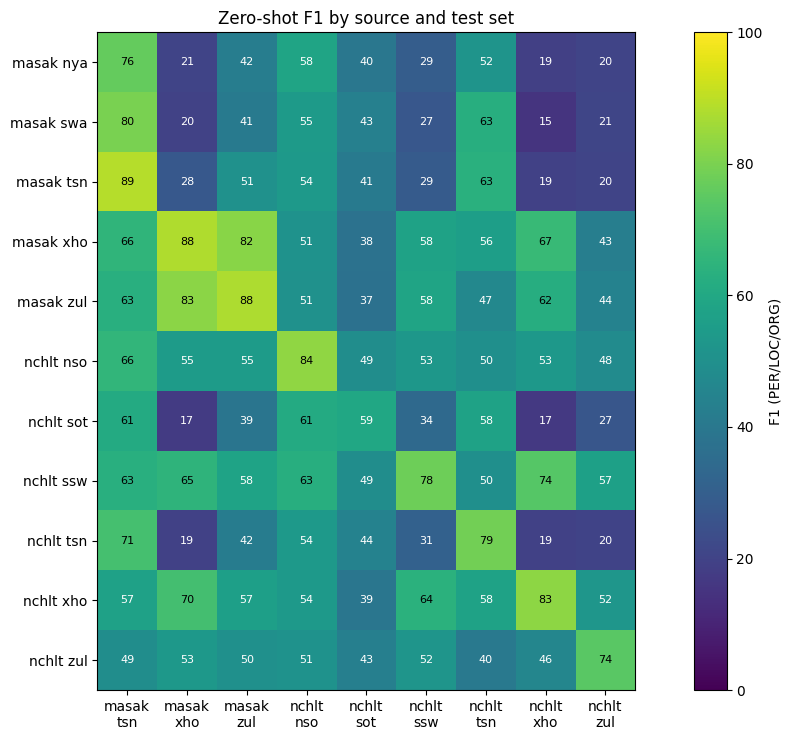

In [ ]:
# Zero-shot F1 heatmap (rows = sources, columns = test sets)
mat = zs.pivot_table(index=["source_corpus", "source_lang"], columns=["test_corpus", "test_lang"], values="f1", aggfunc="mean")
fig, ax = plt.subplots(figsize=(1.0 * mat.shape[1] + 3, 0.5 * mat.shape[0] + 2))
im = ax.imshow(mat.values, cmap="viridis", vmin=0, vmax=100)
ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels([f"{c[0][:5]}\n{c[1]}" for c in mat.columns])
ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels([f"{r[0][:5]} {r[1]}" for r in mat.index])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v < 60 else "black", fontsize=8)
plt.colorbar(im, ax=ax, label="F1 (PER/LOC/ORG)")
ax.set_title("Zero-shot F1 by source and test set")
plt.tight_layout()
plt.savefig(FIG_DIR / "zero_shot_heatmap.png", dpi=150)
plt.show()

### 10.2 RQ1: relatedness vs domain match

In [ ]:
cross = zs[~((zs.relatedness == "same_language") & (zs.domain_match))]
rq1 = cross.groupby(["relatedness", "domain_match"]).agg(
    pairs=("f1", "size"), f1=("f1", "mean"), tr=("transfer_ratio", "mean")).round(2)
rq1 = rq1.reindex([r for r in REL_ORDER if r in rq1.index.get_level_values(0)], level=0)
rq1

pairs     f1    tr
relatedness          domain_match                    
same_language        False            18  60.96  0.73
same_cluster         False            36  56.27  0.68
                     True             42  59.00  0.76
other_southern_bantu False            54  41.36  0.51
                     True             66  43.52  0.56
other_bantu          False            36  36.88  0.49
                     True             18  46.69  0.53

### 10.3 RQ2: seen vs unseen targets

In [ ]:
rq2 = cross.merge(LANGS[["exposure_graded"]], left_on="test_lang", right_index=True)
display_rq2 = rq2.groupby(["target_exposure", "relatedness"]).agg(f1=("f1", "mean"), tr=("transfer_ratio", "mean"), pairs=("f1", "size")).round(2)
display_rq2

f1    tr  pairs
target_exposure relatedness                             
0               other_bantu           55.09  0.66     24
                other_southern_bantu  50.78  0.61     57
                same_cluster          57.80  0.71     33
                same_language         66.95  0.80      6
1               other_bantu           28.19  0.38     30
                other_southern_bantu  35.10  0.47     63
                same_cluster          57.70  0.73     45
                same_language         57.97  0.69     12

### 10.4 RQ3: few-shot learning curves
Gap closure = (F1 at k − F1 at k=0) ÷ (in-language F1 − F1 at k=0).

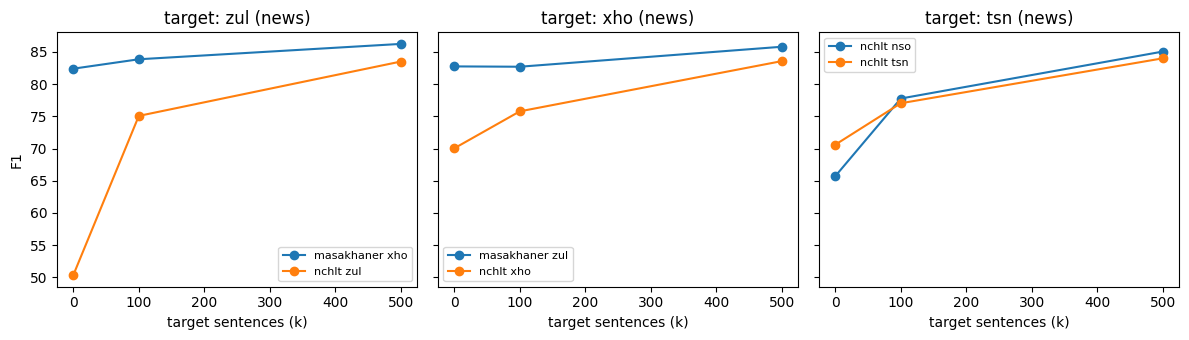

,test_lang,source_corpus,source_lang,k,f1,f1_k0,in_language_f1,gap_closure
0,tsn,nchlt,nso,0,65.706,65.706,89.024,0.000
1,tsn,nchlt,nso,100,77.760,65.706,89.024,0.517
2,tsn,nchlt,nso,500,85.052,65.706,89.024,0.830
3,tsn,nchlt,tsn,0,70.594,70.594,89.024,0.000
4,tsn,nchlt,tsn,100,77.028,70.594,89.024,0.349
5,tsn,nchlt,tsn,500,84.003,70.594,89.024,0.728
6,xho,masakhaner,zul,0,82.744,82.744,88.094,0.000
7,xho,masakhaner,zul,100,82.694,82.744,88.094,-0.009
8,xho,masakhaner,zul,500,85.796,82.744,88.094,0.570
9,xho,nchlt,xho,0,70.031,70.031,88.094,0.000


In [ ]:
fs_pairs = {(*src, *t) for src, ts in FEWSHOT_PLAN.items() for t in ts}
pair_key = list(zip(res.source_corpus, res.source_lang, res.test_corpus, res.test_lang))
curve_rows = res[[k in fs_pairs for k in pair_key]]
curves = curve_rows.groupby(["test_lang", "source_corpus", "source_lang", "k"])["f1"].mean().reset_index()

base = curves[curves.k == 0].set_index(["test_lang", "source_corpus", "source_lang"])["f1"].rename("f1_k0")
curves = curves.join(base, on=["test_lang", "source_corpus", "source_lang"]).join(in_lang.xs("masakhaner"), on="test_lang")
curves["gap_closure"] = (curves.f1 - curves.f1_k0) / (curves.in_language_f1 - curves.f1_k0)

fig, axes = plt.subplots(1, len(NEWS_TARGETS), figsize=(4 * len(NEWS_TARGETS), 3.5), sharey=True)
for ax, tl in zip(np.atleast_1d(axes), NEWS_TARGETS):
    sub = curves[curves.test_lang == tl]
    for (sc, sl), g in sub.groupby(["source_corpus", "source_lang"]):
        ax.plot(g.k, g.f1, marker="o", label=f"{sc} {sl}")
    ax.set_title(f"target: {tl} (news)"); ax.set_xlabel("target sentences (k)"); ax.legend(fontsize=8)
np.atleast_1d(axes)[0].set_ylabel("F1")
plt.tight_layout()
plt.savefig(FIG_DIR / "fewshot_curves.png", dpi=150)
plt.show()
curves.round(3)

### 10.5 RQ4: sources for Setswana

In [ ]:
rq4 = zs[zs.test_lang == "tsn"].groupby(["test_corpus", "source_corpus", "source_lang", "relatedness", "domain_match"]).agg(
    f1=("f1", "mean"), sd=("f1", "std"), tr=("transfer_ratio", "mean")).round(2).sort_values(["test_corpus", "f1"], ascending=[True, False])
rq4

f1    sd    tr
test_corpus source_corpus source_lang relatedness          domain_match                   
masakhaner  masakhaner    tsn         same_language        True          89.02  0.14  1.00
                          swa         other_bantu          True          80.01  2.56  0.90
                          nya         other_bantu          True          76.33  2.21  0.86
            nchlt         tsn         same_language        False         70.59  2.99  0.79
                          nso         same_cluster         False         65.71  1.13  0.74
            masakhaner    xho         other_southern_bantu True          65.59  1.26  0.74
            nchlt         ssw         other_southern_bantu False         63.03  1.94  0.71
            masakhaner    zul         other_southern_bantu True          63.01  1.82  0.71
            nchlt         sot         same_cluster         False         61.05  5.84  0.69
                          xho         other_southern_bantu False         57.22  4.19  0.64
                          zul         other_southern_bantu False         49.03  3.97  0.55
nchlt       nchlt         tsn         same_language        True          78.59  2.05  1.00
            masakhaner    tsn         same_language        False         63.31  0.61  0.81
                          swa         other_bantu          False         62.88  2.62  0.80
            nchlt         sot         same_cluster         True          57.65  2.36  0.73
                          xho         other_southern_bantu True          57.65  3.27  0.73
            masakhaner    xho         other_southern_bantu False         56.06  1.39  0.71
                          nya         other_bantu          False         51.90  0.74  0.66
            nchlt         nso         same_cluster         True          49.86  1.73  0.63
                          ssw         other_southern_bantu True          49.86  1.39  0.63
            masakhaner    zul         other_southern_bantu False         46.77  2.55  0.60
            nchlt         zul         other_southern_bantu True          40.40  0.87  0.51

### 10.6 Statistics
Paired bootstrap over test sentences (1,000 resamples, Holm correction over five pre-specified contrasts), and a mixed-effects regression of transfer ratio with a random intercept for the target language.

In [ ]:
def load_counts(src, test, seed, k=0):
    return pd.read_csv(PRED_DIR / f"{src[0]}-{src[1]}__{test[0]}-{test[1]}__s{seed}__k{k}.csv")

def paired_bootstrap(counts_a, counts_b, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(counts_a)
    base_diff = f1_from_counts(counts_a)["f1"] - f1_from_counts(counts_b)["f1"]
    wins = 0
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if f1_from_counts(counts_a.iloc[idx])["f1"] > f1_from_counts(counts_b.iloc[idx])["f1"]:
            wins += 1
    return {"diff": round(base_diff, 2), "p_one_sided": round(1 - wins / n_boot, 4)}

def holm(pvals):
    order = np.argsort(pvals)
    m, adj, running = len(pvals), np.empty(len(pvals)), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * pvals[i]))
        adj[i] = running
    return adj

In [ ]:
# Pre-specified contrasts: (description, system A, system B, test set). Edit to match the final design.
# The pre-specified hypothesis is one-sided: A beats B (related / sister source beats the alternative).
CONTRASTS = [
    ("RQ1 zul news: sister news vs same-language gov", ("masakhaner", "xho"), ("nchlt", "zul"), ("masakhaner", "zul")),
    ("RQ1 xho news: sister news vs same-language gov", ("masakhaner", "zul"), ("nchlt", "xho"), ("masakhaner", "xho")),
    ("RQ4 tsn news: Sepedi vs Swahili",                ("nchlt", "nso"),       ("masakhaner", "swa"), ("masakhaner", "tsn")),
    ("RQ4 tsn news: Sesotho vs Swahili",               ("nchlt", "sot"),       ("masakhaner", "swa"), ("masakhaner", "tsn")),
    ("RQ4 tsn gov: Sepedi vs Swahili",                 ("nchlt", "nso"),       ("masakhaner", "swa"), ("nchlt", "tsn")),
]

def paired_bootstrap_seeds(a, b, test, seeds, n_boot=1000, rng_seed=0):
    # One test per contrast. Every resample draws the same test sentences for all seeds, then
    # averages F1 over seeds for each system, so the seeds are pooled rather than tested separately.
    ca = [load_counts(a, test, s) for s in seeds]
    cb = [load_counts(b, test, s) for s in seeds]
    n = len(ca[0])
    mean_f1 = lambda cs, idx: np.mean([f1_from_counts(c.iloc[idx])["f1"] for c in cs])
    all_idx = np.arange(n)
    base_diff = mean_f1(ca, all_idx) - mean_f1(cb, all_idx)
    per_seed = [round(f1_from_counts(x)["f1"] - f1_from_counts(y)["f1"], 1) for x, y in zip(ca, cb)]
    rng = np.random.default_rng(rng_seed)
    wins = sum(mean_f1(ca, idx) > mean_f1(cb, idx) for idx in (rng.integers(0, n, n) for _ in range(n_boot)))
    # Add-one resampling p-values: a bootstrap with n_boot draws cannot show p below 1 / (n_boot + 1)
    p_one = (n_boot - wins + 1) / (n_boot + 1)                    # H1: A beats B
    p_two = min(1.0, 2 * min(wins + 1, n_boot - wins + 1) / (n_boot + 1))  # either direction
    return {"diff_mean_over_seeds": round(base_diff, 2), "diff_per_seed": per_seed,
            "p_one_sided": round(p_one, 4), "p_two_sided": round(p_two, 4)}

rows = []
for desc, a, b, test in CONTRASTS:
    try:
        rows.append({"contrast": desc, **paired_bootstrap_seeds(a, b, test, SEEDS)})
    except FileNotFoundError:
        pass

if rows:
    boot = pd.DataFrame(rows)
    boot["p_holm"] = holm(boot["p_one_sided"].values)           # pre-specified one-sided test, across contrasts
    boot["p_holm_two_sided"] = holm(boot["p_two_sided"].values)  # reported when the observed direction is reversed
    boot.to_csv(RESULTS_DIR / "bootstrap_contrasts.csv", index=False)
    display(boot)
else:
    print("No contrast results yet. Run section 9 first.")

,contrast,diff_mean_over_seeds,diff_per_seed,p_one_sided,p_two_sided,p_holm,p_holm_two_sided
0,RQ1 zul news: sister news vs same-language gov,32.04,"[37.2, 31.4, 27.6]",0.001,0.002,0.005,0.01
1,RQ1 xho news: sister news vs same-language gov,12.71,"[12.7, 12.7, 12.8]",0.001,0.002,0.005,0.01
2,RQ4 tsn news: Sepedi vs Swahili,-14.31,"[-14.6, -12.7, -15.5]",1.000,0.002,1.000,0.01
3,RQ4 tsn news: Sesotho vs Swahili,-18.96,"[-16.5, -22.9, -17.4]",1.000,0.002,1.000,0.01
4,RQ4 tsn gov: Sepedi vs Swahili,-13.02,"[-12.8, -11.3, -14.9]",1.000,0.002,1.000,0.01


In [ ]:
import statsmodels.formula.api as smf

# rel_score: 3 = same language, 2 = same cluster, 1 = other Southern Bantu, 0 = other Bantu.
# An ordinal score keeps the model small; with few cells, a full categorical interaction may not be estimable.
# One row per source-test pair: the three seeds are averaged first. Using the per-seed rows would count every pair
# three times as if independent and make the standard errors too small.
PAIR = ["source_corpus", "source_lang", "test_corpus", "test_lang"]
reg = (cross.dropna(subset=["transfer_ratio"])
       .groupby(PAIR, as_index=False)
       .agg(transfer_ratio=("transfer_ratio", "mean"), rel_score=("rel_score", "first"),
            domain_match=("domain_match", "first"), target_exposure=("target_exposure", "first"),
            entity_overlap=("entity_overlap", "first"), n_seeds=("seed", "nunique")))
reg["domain_match"] = reg["domain_match"].astype(int)

RQ12_FORMULA = "transfer_ratio ~ rel_score * domain_match + target_exposure + entity_overlap"
n_params = 6  # intercept, rel_score, domain_match, interaction, target_exposure, entity_overlap

# transfer_ratio is NaN for any target without an in-language (source = target) run,
# so in a dry run or with missing corpora this table can be empty or too small to fit.
if reg.empty or reg["test_lang"].nunique() < 2 or len(reg) <= n_params:
    print(f"Skipping mixed-effects model: {len(reg)} usable rows across "
          f"{reg['test_lang'].nunique()} target language(s). "
          "Needs in-language runs for each target and more source-target pairs (full run with NCHLT data).")
    fit = None
else:
    print(f"{len(reg)} source-test pairs (seed-averaged, {reg.n_seeds.min()}-{reg.n_seeds.max()} seeds each), "
          f"{reg['test_lang'].nunique()} target-language groups")
    model_rq12 = smf.mixedlm(RQ12_FORMULA, data=reg, groups=reg["test_lang"])
    fit = model_rq12.fit()
    print(fit.summary())

90 source-test pairs (seed-averaged, 3-3 seeds each), 6 target-language groups
              Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  transfer_ratio
No. Observations:    90       Method:              REML          
No. Groups:          6        Scale:               0.0223        
Min. group size:     10       Log-Likelihood:      29.4722       
Max. group size:     20       Converged:           Yes           
Mean group size:     15.0                                        
-----------------------------------------------------------------
                       Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-----------------------------------------------------------------
Intercept               0.490    0.067  7.270 0.000  0.358  0.622
rel_score               0.101    0.025  4.111 0.000  0.053  0.149
domain_match            0.023    0.060  0.378 0.705 -0.095  0.140
rel_score:domain_match  0.012    0.046  0.269 0.788 -0.079  0.104
target_expo

/tmp/ipykernel_2567/145444293.py:29: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  fit = model_rq12.fit()


### 10.7 Comparison with the published baseline

### 10.8 Robustness checks
Corpus terms and the tokenizer-fertility gap in the regression, and the share of gold entities lost to truncation at 128 subwords.

In [ ]:
# (a) and (b): re-fit the RQ1/RQ2 model with source corpus and test corpus as separate terms, then add the fertility gap.
# Uses `reg` from 10.6 (one row per source-test pair, seed-averaged).

def corpus_fertility(sents, max_sents=2000):
    pieces = words = 0
    for s in sents[:max_sents]:
        for w in s["tokens"]:
            pieces += len(tokenizer.tokenize(w)); words += 1
    return pieces / max(words, 1)

FERT = {key: corpus_fertility(d["train"]) for key, d in CORPORA.items()}  # per (corpus, language), deduplicated train
reg2 = reg.copy()
reg2["fert_gap"] = [abs(FERT[(r.source_corpus, r.source_lang)] - FERT[(r.test_corpus, r.test_lang)]) for r in reg2.itertuples()]
reg2["src_news"] = (reg2.source_corpus == "masakhaner").astype(int)
reg2["test_news"] = (reg2.test_corpus == "masakhaner").astype(int)

MODELS_10_8 = {
    "M0 (10.6 model)":           "transfer_ratio ~ rel_score * domain_match + target_exposure + entity_overlap",
    "M1 corpus terms":           "transfer_ratio ~ rel_score + src_news * test_news + target_exposure + entity_overlap",
    "M2 corpus terms + fert gap": "transfer_ratio ~ rel_score + src_news * test_news + target_exposure + entity_overlap + fert_gap",
}
fits_10_8 = {}
for name, formula in MODELS_10_8.items():
    f = smf.mixedlm(formula, data=reg2, groups=reg2["test_lang"]).fit(reml=False)  # ML, so log-likelihoods are comparable
    fits_10_8[name] = f
    print(f"=== {name}: {formula}   (log-likelihood {f.llf:.1f}, AIC {f.aic:.1f})")
    print(pd.DataFrame({"coef": f.params, "se": f.bse, "p": f.pvalues}).drop(index="Group Var", errors="ignore").round(3).to_string())
    print()
print("fertility per corpus:", {f"{c}-{l}": round(v, 2) for (c, l), v in sorted(FERT.items())})

=== M0 (10.6 model): transfer_ratio ~ rel_score * domain_match + target_exposure + entity_overlap   (log-likelihood 41.1, AIC -66.3)
                         coef     se      p
Intercept               0.488  0.056  0.000
rel_score               0.098  0.024  0.000
domain_match            0.022  0.059  0.712
rel_score:domain_match  0.009  0.045  0.847
target_exposure        -0.078  0.063  0.218
entity_overlap          0.480  0.616  0.436

=== M1 corpus terms: transfer_ratio ~ rel_score + src_news * test_news + target_exposure + entity_overlap   (log-likelihood 44.6, AIC -71.2)
                     coef     se      p
Intercept           0.458  0.063  0.000
rel_score           0.112  0.023  0.000
src_news            0.016  0.042  0.700
test_news           0.014  0.049  0.776
src_news:test_news  0.113  0.073  0.119
target_exposure    -0.085  0.067  0.205
entity_overlap      0.660  0.528  0.211

=== M2 corpus terms + fert gap: transfer_ratio ~ rel_score + src_news * test_news + target_expos

/tmp/ipykernel_2567/2614110397.py:24: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  f = smf.mixedlm(formula, data=reg2, groups=reg2["test_lang"]).fit(reml=False)  # ML, so log-likelihoods are comparable
/tmp/ipykernel_2567/2614110397.py:24: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  f = smf.mixedlm(formula, data=reg2, groups=reg2["test_lang"]).fit(reml=False)  # ML, so log-likelihoods are comparable
/tmp/ipykernel_2567/2614110397.py:24: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  f = smf.mixedlm(formula, data=reg2, groups=reg2["test_lang"]).fit(reml=False)  # ML, so log-likelihoods are comparable


In [ ]:
# (c) How many gold entities does truncation at MAX_LENGTH make unreachable? (predict() labels cut-off words as "O")
rows = []
for test in TEST_SETS:
    sents = CORPORA[test]["test"]
    enc = tokenizer([s["tokens"] for s in sents], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    n_ent = lost = trunc_sents = 0
    for i, s in enumerate(sents):
        kept = {w for w in enc.word_ids(batch_index=i) if w is not None}
        spans = entity_spans(mask_excluded(s["tags"], s["tags"])[0])
        n_ent += len(spans)
        lost_here = sum(1 for _, a, b in spans if any(w not in kept for w in range(a, b)))
        lost += lost_here
        trunc_sents += len(kept) < len(s["tokens"])
    rows.append({"test_corpus": test[0], "test_lang": test[1], "sentences": len(sents), "truncated_sentences": trunc_sents,
                 "gold_entities": n_ent, "entities_lost": lost, "pct_lost": round(100 * lost / max(n_ent, 1), 2)})
trunc_df = pd.DataFrame(rows)
trunc_df.to_csv(RESULTS_DIR / "truncation_check.csv", index=False)
trunc_df

,test_corpus,test_lang,sentences,truncated_sentences,gold_entities,entities_lost,pct_lost
0,nchlt,zul,1086,27,989,9,0.91
1,nchlt,xho,618,21,342,2,0.58
2,nchlt,ssw,1052,29,999,16,1.60
3,nchlt,nso,698,19,708,7,0.99
4,nchlt,sot,937,35,805,10,1.24
5,nchlt,tsn,778,37,502,14,2.79
6,masakhaner,zul,1670,0,1598,0,0.00
7,masakhaner,xho,1633,0,2553,0,0.00
8,masakhaner,tsn,996,2,1327,0,0.00


### 10.9 RQ4 with an equal number of entity spans per source
Each RQ4 source is retrained on about 2,500 PER/LOC/ORG spans instead of 3,000 sentences.

In [ ]:
# RQ4 re-run with an equal number of entity spans per source (resumable; backed up to Drive after every source)
RQ4_CAP_SOURCES = [("nchlt", "nso"), ("nchlt", "sot"), ("masakhaner", "swa"), ("masakhaner", "nya"), ("nchlt", "xho")]
CAP_FILE = RESULTS_DIR / "results_entity_cap.csv"
CAP_PRED_DIR = PRED_DIR / "entity_cap"
CAP_PRED_DIR.mkdir(parents=True, exist_ok=True)

def n_spans(sents):
    return sum(len(entity_spans(s["tags"])) for s in sents)

available = {src: n_spans(CORPORA[src]["train"]) for src in RQ4_CAP_SOURCES}
ENTITY_CAP = min(2500, min(available.values()))  # every source must be able to reach the cap
print("entity spans available in train:", available, "| ENTITY_CAP =", ENTITY_CAP)

def sample_by_entities(sents, cap, seed):
    idx = list(range(len(sents)))
    random.Random(seed).shuffle(idx)
    out, total = [], 0
    for i in idx:
        if total >= cap:
            break
        out.append(sents[i]); total += len(entity_spans(sents[i]["tags"]))
    return out, total

def cap_done():
    if not CAP_FILE.exists():
        return set()
    d = pd.read_csv(CAP_FILE)
    return set(zip(d.source_corpus, d.source_lang, d.test_corpus, d.test_lang, d.seed))

t0 = time.time()
for seed in SEEDS:
    for src in RQ4_CAP_SOURCES:
        todo = [t for t in TEST_SETS if (*src, *t, seed) not in cap_done()]
        if not todo:
            print("skip", src, seed); continue
        train_sents, got = sample_by_entities(CORPORA[src]["train"], ENTITY_CAP, seed)
        model = new_model().cuda() if torch.cuda.is_available() else new_model()
        train(model, train_sents, seed, TRAIN_ARGS["num_train_epochs"], RESULTS_DIR / "tmp")
        for t in todo:
            gold = CORPORA[t]["test"]
            counts = sentence_counts(gold, predict(model, gold))
            run_id = f"{src[0]}-{src[1]}__{t[0]}-{t[1]}__s{seed}__cap{ENTITY_CAP}"
            counts.to_csv(CAP_PRED_DIR / f"{run_id}.csv", index=False)
            row = {"run_id": run_id, "source_corpus": src[0], "source_lang": src[1], "test_corpus": t[0], "test_lang": t[1],
                   "seed": seed, "entity_cap": ENTITY_CAP, "train_sentences": len(train_sents), "train_spans": got,
                   "train_tokens": sum(len(s["tokens"]) for s in train_sents), **f1_from_counts(counts)}
            pd.DataFrame([row]).to_csv(CAP_FILE, mode="a", header=not CAP_FILE.exists(), index=False)
        print(f"{src} seed {seed}: {len(train_sents)} sentences, {got} spans | "
              f"tsn news {pd.read_csv(CAP_FILE).query('source_lang == @src[1] and source_corpus == @src[0] and seed == @seed and test_lang == \"tsn\"').set_index('test_corpus')['f1'].round(1).to_dict()}")
        del model; torch.cuda.empty_cache()
        backup_results()
print(f"done in {(time.time() - t0) / 60:.1f} min | rows: {len(pd.read_csv(CAP_FILE))} (expected {len(RQ4_CAP_SOURCES) * len(TEST_SETS) * len(SEEDS)})")

entity spans available in train: {('nchlt', 'nso'): 5658, ('nchlt', 'sot'): 6175, ('masakhaner', 'swa'): 12230, ('masakhaner', 'nya'): 9908, ('nchlt', 'xho'): 2620} | ENTITY_CAP = 2500


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.491329
100,0.153388
150,0.096487
200,0.066990
250,0.065723
300,0.057625
350,0.038163
400,0.032477
450,0.032076


('nchlt', 'nso') seed 13: 2431 sentences, 2502 spans | tsn news {'nchlt': 48.8, 'masakhaner': 65.3}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

... (51 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: Davlan/afro-xlmr-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
classifier.weight         | MISSING    | 
classifier.bias           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
50,0.540298
100,0.137857
150,0.100657
200,0.062701
250,0.054720
300,0.041971
350,0.031980
400,0.030540
450,0.034749
500,0.033086


('nchlt', 'xho') seed 2026: 4683 sentences, 2500 spans | tsn news {'nchlt': 58.0, 'masakhaner': 60.0}
done in 23.0 min | rows: 135 (expected 135)


In [ ]:
# Back up the analysis outputs (results_enriched.csv, bootstrap_contrasts.csv, covariates) and the figures to Drive
import shutil
if BACKUP_RESULTS is not None:
    shutil.copytree(RESULTS_DIR, BACKUP_RESULTS, dirs_exist_ok=True, ignore=shutil.ignore_patterns("tmp"))
    shutil.copytree(FIG_DIR, BACKUP_RESULTS.parent / "figures", dirs_exist_ok=True)
    print("backed up results and figures to", BACKUP_RESULTS.parent)
    print("rows in Drive results.csv:", len(pd.read_csv(BACKUP_RESULTS / "results.csv")))
else:
    print("Drive not mounted: nothing backed up")

backed up results and figures to /content/drive/MyDrive/COS802_project_backup/v2_deduplicated
rows in Drive results.csv: 333


In [ ]:
# The published "best single source" is always a DIFFERENT language (e.g. xho for zul), so the fair counterpart
# of ours excludes same-language sources (both corpora). Our in-language F1 is shown separately.
ours = (zs[(zs.test_corpus == "masakhaner") & (zs.source_lang != zs.test_lang)]
        .groupby(["test_lang", "source_corpus", "source_lang"])["f1"].mean().reset_index())
best_ours = (ours.loc[ours.groupby("test_lang")["f1"].idxmax()]
             .rename(columns={"test_lang": "target", "f1": "our_best_f1", "source_lang": "our_best_source",
                              "source_corpus": "our_best_source_corpus"}))
our_in_language = in_lang.xs("masakhaner").rename("our_in_language_f1")  # same-language, same-corpus, seed mean

comparison = (PUBLISHED_BASELINE
              .merge(best_ours[["target", "our_best_source_corpus", "our_best_source", "our_best_f1"]], on="target", how="left")
              .join(our_in_language, on="target"))
comparison["ours_minus_published_best"] = comparison.our_best_f1 - comparison.best_source_f1
comparison.round(2)

,target,best_source,best_source_f1,english_f1,in_language_f1,transfer_ratio,our_best_source_corpus,our_best_source,our_best_f1,our_in_language_f1,ours_minus_published_best
0,zul,xho,82.1,44.7,88.6,0.93,masakhaner,xho,82.39,87.63,0.29
1,xho,zul,83.7,24.5,90.8,0.92,masakhaner,zul,82.74,88.09,-0.96
2,tsn,deu,73.3,65.8,88.7,0.83,masakhaner,swa,80.01,89.02,6.71
